# EDA: German Credit и QSAR biodegradation

Цель: исследовать исходные датасеты. Ноутбук проверяет размерность, целевую переменную, баланс классов, типы признаков, пропуски, дубликаты и потенциальные выбросы.

## 1. Импорты и пути

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = PROJECT_ROOT / "data" / "raw"
REPORT_DIR = PROJECT_ROOT / "results" / "processed" / "eda"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

GERMAN_PATH = RAW_DIR / "german_credit.csv"
QSAR_PATH = RAW_DIR / "qsar_biodegradation.csv"

sns.set_theme()
pd.set_option("display.max_columns", 100)

print("Project root:", PROJECT_ROOT)
print("German Credit:", GERMAN_PATH.exists())
print("QSAR:", QSAR_PATH.exists())

Project root: C:\Users\nicon\Desktop\hpo-ga-benchmark
German Credit: True
QSAR: True


## 2. Загрузка данных

In [2]:
if not GERMAN_PATH.exists() or not QSAR_PATH.exists():
    raise FileNotFoundError("Не найдены CSV в data/raw. Сначала выполните скрипт загрузки.")

german = pd.read_csv(GERMAN_PATH)
qsar = pd.read_csv(QSAR_PATH)
datasets = {"German Credit": german, "QSAR biodegradation": qsar}
TARGET = "target"

for name, df in datasets.items():
    print(f"\n{name}: shape={df.shape}")
    display(df.head())


German Credit: shape=(1000, 21)


,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,Attribute11,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20,target
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201,2



QSAR biodegradation: shape=(1055, 42)


,SpMax_L,J_Dz(e),nHM,F01[N-N],F04[C-N],NssssC,nCb-,C%,nCp,nO,F03[C-N],SdssC,HyWi_B(m),LOC,SM6_L,F03[C-O],Me,Mi,nN-N,nArNO2,nCRX3,SpPosA_B(p),nCIR,B01[C-Br],B03[C-Cl],N-073,SpMax_A,Psi_i_1d,B04[C-Br],SdO,TI2_L,nCrt,C-026,F02[C-N],nHDon,SpMax_B(m),Psi_i_A,nN,SM6_B(m),nArCOOR,nX,target
0,3.919,2.6909,0,0,0,0,0,31.4,2,0,0,0.000,3.106,2.550,9.002,0,0.960,1.142,0,0,0,1.201,0,0,0,0,1.932,0.011,0,0.000,4.489,0,0,0,0,2.949,1.591,0,7.253,0,0,RB
1,4.170,2.1144,0,0,0,0,0,30.8,1,1,0,0.000,2.461,1.393,8.723,1,0.989,1.144,0,0,0,1.104,1,0,0,0,2.214,-0.204,0,0.000,1.542,0,0,0,0,3.315,1.967,0,7.257,0,0,RB
2,3.932,3.2512,0,0,0,0,0,26.7,2,4,0,0.000,3.279,2.585,9.110,0,1.009,1.152,0,0,0,1.092,0,0,0,0,1.942,-0.008,0,0.000,4.891,0,0,0,1,3.076,2.417,0,7.601,0,0,RB
3,3.000,2.7098,0,0,0,0,0,20.0,0,2,0,0.000,2.100,0.918,6.594,0,1.108,1.167,0,0,0,1.024,0,0,0,0,1.414,1.073,0,8.361,1.333,0,0,0,1,3.046,5.000,0,6.690,0,0,RB
4,4.236,3.3944,0,0,0,0,0,29.4,2,4,0,-0.271,3.449,2.753,9.528,2,1.004,1.147,0,0,0,1.137,0,0,0,0,1.985,-0.002,0,10.348,5.588,0,0,0,0,3.351,2.405,0,8.003,0,0,RB


## 3. Распределение классов

In [3]:
for name, df in datasets.items():
    if TARGET not in df.columns:
        raise ValueError(f"{name}: отсутствует столбец {TARGET!r}")
    print(f"\n{name}:")
    display(pd.DataFrame({
        "count": df[TARGET].value_counts(dropna=False),
        "proportion": df[TARGET].value_counts(normalize=True, dropna=False)
    }))


German Credit:


,count,proportion
target,,
1,700,0.7
2,300,0.3



QSAR biodegradation:


,count,proportion
target,,
NRB,699,0.662559
RB,356,0.337441


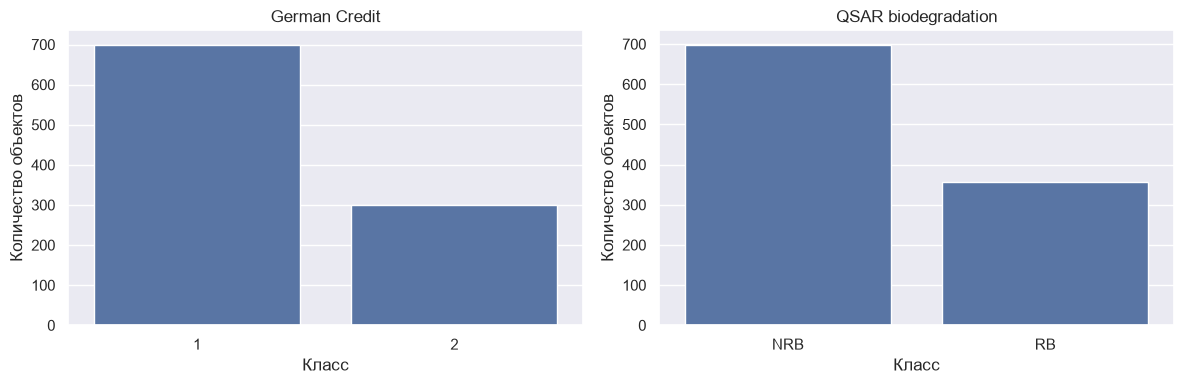

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, df) in zip(axes, datasets.items()):
    sns.countplot(data=df, x=TARGET, order=df[TARGET].value_counts().index, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Класс")
    ax.set_ylabel("Количество объектов")
    ax.tick_params(axis="x")
plt.tight_layout()
plt.show()

## 4. Размерность и типы признаков

In [5]:
for name, df in datasets.items():
    X = df.drop(columns=TARGET)
    print(f"\n{name}: объектов={len(df)}, признаков={X.shape[1]}")
    display(pd.DataFrame({
        "dtype": X.dtypes.astype(str),
        "n_unique": X.nunique(dropna=True),
        "missing": X.isna().sum()
    }).sort_values(["dtype", "n_unique"]))


German Credit: объектов=1000, признаков=20


,dtype,n_unique,missing
Attribute18,int64,2,0
Attribute8,int64,4,0
Attribute11,int64,4,0
Attribute16,int64,4,0
Attribute2,int64,33,0
Attribute13,int64,53,0
Attribute5,int64,921,0
Attribute19,str,2,0
Attribute20,str,2,0
Attribute10,str,3,0



QSAR biodegradation: объектов=1055, признаков=41


,dtype,n_unique,missing
Mi,float64,125,0
Me,float64,167,0
C%,float64,188,0
Psi_i_1d,float64,205,0
SpMax_A,float64,329,0
SpPosA_B(p),float64,352,0
LOC,float64,373,0
SdssC,float64,384,0
SpMax_L,float64,440,0
SdO,float64,470,0


## 5. Пропущенные значения

In [6]:
for name, df in datasets.items():
    report = pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percent": (df.isna().mean() * 100).round(3)
    })
    report = report[report["missing_count"] > 0].sort_values("missing_count", ascending=False)
    print(f"\n{name}")
    display(report) if not report.empty else print("Пропусков не обнаружено.")


German Credit
Пропусков не обнаружено.

QSAR biodegradation
Пропусков не обнаружено.


## 6. Дубликаты

In [7]:
for name, df in datasets.items():
    print(
        f"{name}: полных дубликатов={df.duplicated().sum()}, "
        f"дубликатов признаков без target={df.drop(columns=TARGET).duplicated().sum()}"
    )

German Credit: полных дубликатов=0, дубликатов признаков без target=0
QSAR biodegradation: полных дубликатов=3, дубликатов признаков без target=3


## 7. Описательная статистика числовых признаков

In [8]:
for name, df in datasets.items():
    numeric = df.drop(columns=TARGET).select_dtypes(include=np.number)
    print(f"\n{name}")
    display(numeric.describe().T)


German Credit


,count,mean,std,min,25%,50%,75%,max
Attribute2,1000.0,20.903,12.058814,4.0,12.0,18.0,24.00,72.0
Attribute5,1000.0,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
Attribute8,1000.0,2.973,1.118715,1.0,2.0,3.0,4.00,4.0
Attribute11,1000.0,2.845,1.103718,1.0,2.0,3.0,4.00,4.0
Attribute13,1000.0,35.546,11.375469,19.0,27.0,33.0,42.00,75.0
Attribute16,1000.0,1.407,0.577654,1.0,1.0,1.0,2.00,4.0
Attribute18,1000.0,1.155,0.362086,1.0,1.0,1.0,1.00,2.0



QSAR biodegradation


,count,mean,std,min,25%,50%,75%,max
SpMax_L,1055.0,4.782644,0.546916,2.0000,4.48100,4.8280,5.12500,6.4960
J_Dz(e),1055.0,3.069508,0.831308,0.8039,2.50275,3.0463,3.43765,9.1775
nHM,1055.0,0.716588,1.462452,0.0000,0.00000,0.0000,1.00000,12.0000
F01[N-N],1055.0,0.042654,0.256010,0.0000,0.00000,0.0000,0.00000,3.0000
F04[C-N],1055.0,0.980095,2.332955,0.0000,0.00000,0.0000,1.00000,36.0000
NssssC,1055.0,0.290047,1.073771,0.0000,0.00000,0.0000,0.00000,13.0000
nCb-,1055.0,1.646445,2.224822,0.0000,0.00000,1.0000,3.00000,18.0000
C%,1055.0,37.055640,9.144466,0.0000,30.45000,37.5000,43.40000,60.7000
nCp,1055.0,1.376303,1.963521,0.0000,0.00000,1.0000,2.00000,24.0000
nO,1055.0,1.803791,1.775435,0.0000,0.00000,2.0000,3.00000,12.0000


## 8. Выбросы по IQR

Границы: Q1 - 1.5 × IQR и Q3 + 1.5 × IQR.

In [9]:
def iqr_outlier_report(df, target=TARGET):
    numeric = df.drop(columns=target).select_dtypes(include=np.number)
    rows = []
    for column in numeric.columns:
        values = numeric[column].dropna()
        if values.empty:
            continue
        q1, q3 = values.quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        count = int(((values < lower) | (values > upper)).sum())
        rows.append({
            "feature": column, "q1": q1, "q3": q3, "iqr": iqr,
            "lower_bound": lower, "upper_bound": upper,
            "outlier_count": count,
            "outlier_percent": 100 * count / len(values)
        })
    return pd.DataFrame(rows).sort_values("outlier_count", ascending=False)

outlier_reports = {}
for name, df in datasets.items():
    outlier_reports[name] = iqr_outlier_report(df)
    print(f"\n{name}")
    display(outlier_reports[name])


German Credit


,feature,q1,q3,iqr,lower_bound,upper_bound,outlier_count,outlier_percent
6,Attribute18,1.0,1.00,0.00,1.000,1.000,155,15.5
1,Attribute5,1365.5,3972.25,2606.75,-2544.625,7882.375,72,7.2
0,Attribute2,12.0,24.00,12.00,-6.000,42.000,70,7.0
4,Attribute13,27.0,42.00,15.00,4.500,64.500,23,2.3
5,Attribute16,1.0,2.00,1.00,-0.500,3.500,6,0.6
2,Attribute8,2.0,4.00,2.00,-1.000,7.000,0,0.0
3,Attribute11,2.0,4.00,2.00,-1.000,7.000,0,0.0



QSAR biodegradation


,feature,q1,q3,iqr,lower_bound,upper_bound,outlier_count,outlier_percent
27,Psi_i_1d,-0.00800,0.00500,0.0130,-0.02750,0.02450,298,28.246445
11,SdssC,-0.19100,0.00000,0.1910,-0.47750,0.28650,250,23.696682
40,nX,0.00000,0.00000,0.0000,0.00000,0.00000,232,21.990521
24,B03[C-Cl],0.00000,0.00000,0.0000,0.00000,0.00000,156,14.786730
5,NssssC,0.00000,0.00000,0.0000,0.00000,0.00000,149,14.123223
32,C-026,0.00000,1.00000,1.0000,-1.50000,2.50000,126,11.943128
4,F04[C-N],0.00000,1.00000,1.0000,-1.50000,2.50000,123,11.658768
2,nHM,0.00000,1.00000,1.0000,-1.50000,2.50000,93,8.815166
10,F03[C-N],0.00000,2.00000,2.0000,-3.00000,5.00000,83,7.867299
35,SpMax_B(m),3.48750,3.98700,0.4995,2.73825,4.73625,81,7.677725


## 9. Boxplots числовых признаков

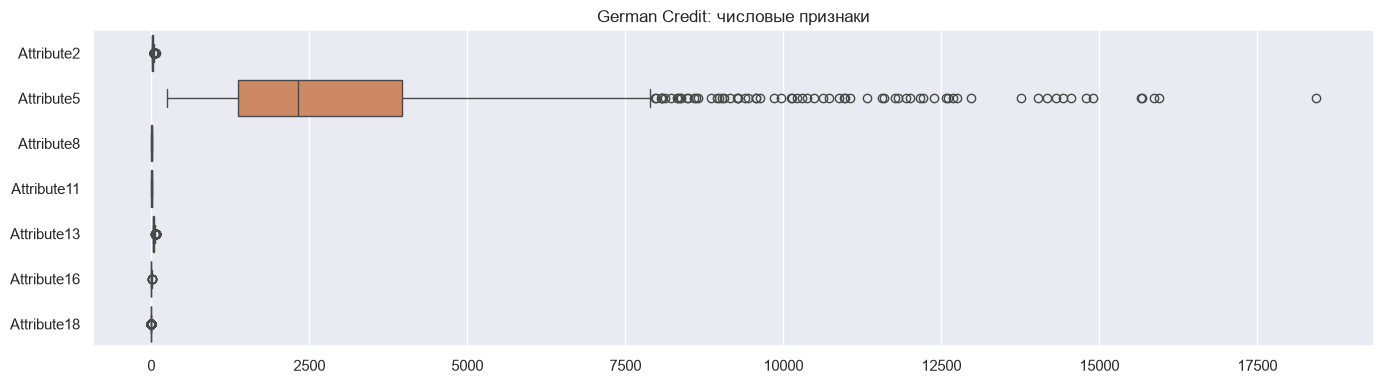

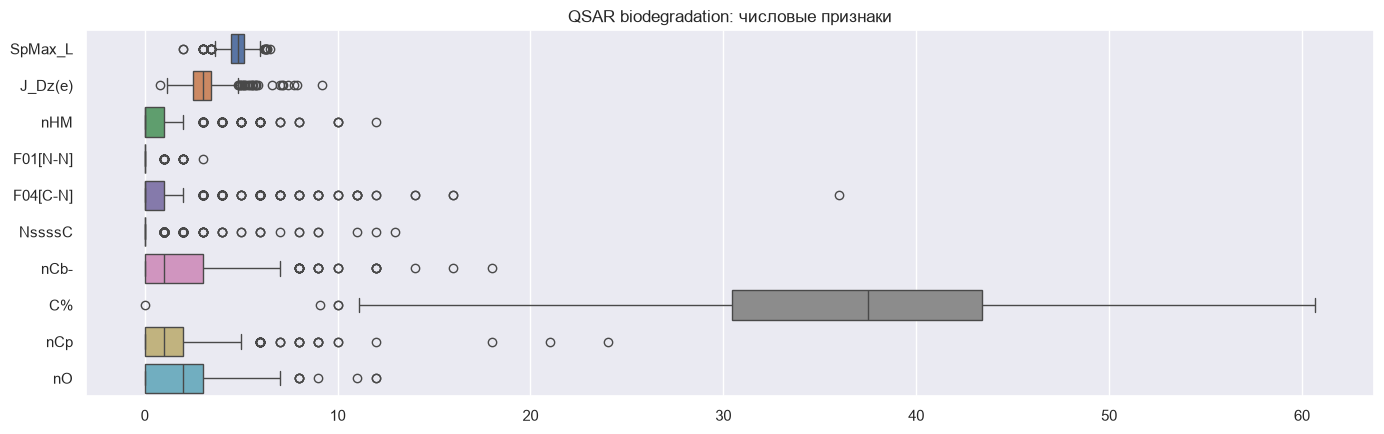

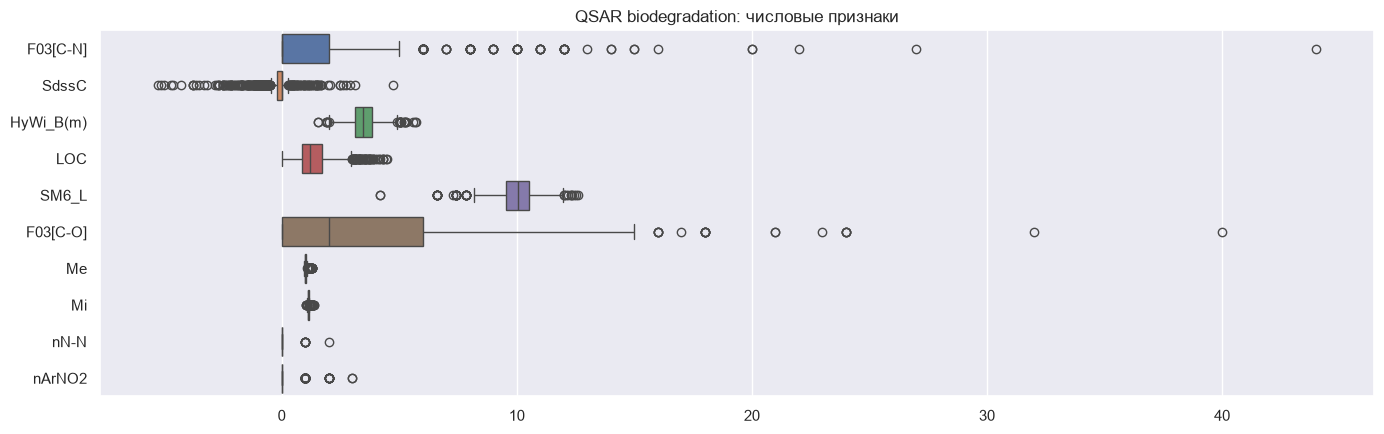

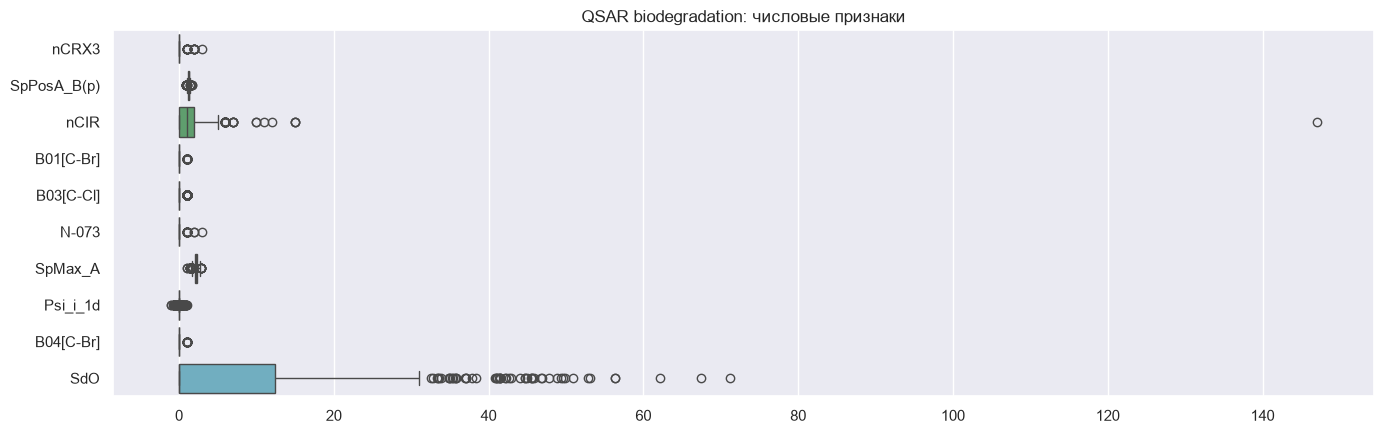

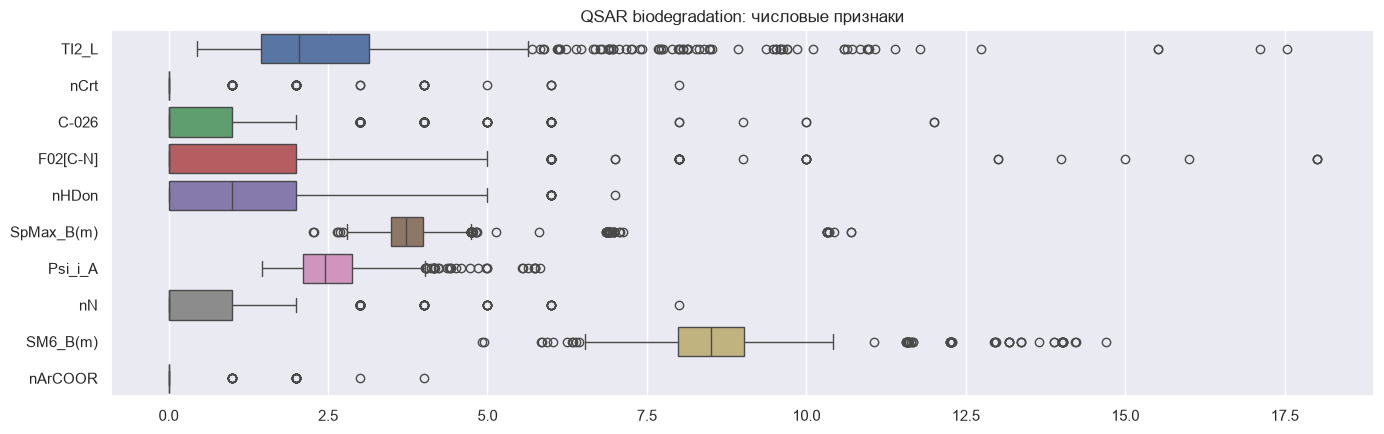

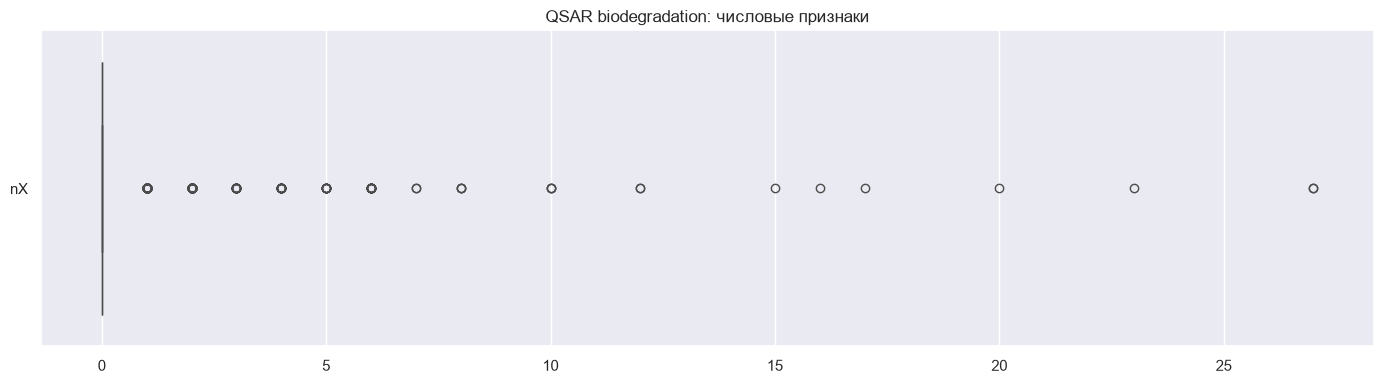

In [10]:
for name, df in datasets.items():
    columns = df.drop(columns=TARGET).select_dtypes(include=np.number).columns.tolist()
    for start in range(0, len(columns), 10):
        subset = columns[start:start + 10]
        if not subset:
            continue
        plt.figure(figsize=(14, max(4, len(subset) * 0.45)))
        sns.boxplot(data=df[subset], orient="h")
        plt.title(f"{name}: числовые признаки")
        plt.tight_layout()
        plt.show()

## 10. Категориальные признаки German Credit

In [11]:
german_categorical = german.drop(columns=TARGET).select_dtypes(
    include=["object", "str", "category", "bool"]
).columns.tolist()

print("Категориальные по dtype:", german_categorical)
for column in german_categorical:
    print(f"\n{column}")
    display(german[column].value_counts(dropna=False).to_frame("count"))

Категориальные по dtype: ['Attribute1', 'Attribute3', 'Attribute4', 'Attribute6', 'Attribute7', 'Attribute9', 'Attribute10', 'Attribute12', 'Attribute14', 'Attribute15', 'Attribute17', 'Attribute19', 'Attribute20']

Attribute1


,count
Attribute1,
A14,394
A11,274
A12,269
A13,63



Attribute3


,count
Attribute3,
A32,530
A34,293
A33,88
A31,49
A30,40



Attribute4


,count
Attribute4,
A43,280
A40,234
A42,181
A41,103
A49,97
A46,50
A45,22
A44,12
A410,12


... (16 outputs left out)


Attribute19


,count
Attribute19,
A191,596
A192,404



Attribute20


,count
Attribute20,
A201,963
A202,37


## 11. Сохранение отчётов EDA

In [12]:
for name, df in datasets.items():
    safe_name = name.lower().replace(" ", "_").replace("-", "_")
    columns_report = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_unique": df.nunique(dropna=True),
        "missing_count": df.isna().sum(),
        "missing_percent": (df.isna().mean() * 100).round(3)
    })
    columns_report.to_csv(REPORT_DIR / f"{safe_name}_columns.csv")
    outlier_reports[name].to_csv(
        REPORT_DIR / f"{safe_name}_outliers_iqr.csv", index=False
    )
    class_report = df[TARGET].value_counts(dropna=False).rename_axis("class").reset_index(name="count")
    class_report["proportion"] = class_report["count"] / len(df)
    class_report.to_csv(REPORT_DIR / f"{safe_name}_class_distribution.csv", index=False)

print("Отчёты сохранены")

Отчёты сохранены


## 12. Итоги EDA

### Сводная таблица по датасетам

| Характеристика                    | German Credit                                    | QSAR biodegradation                           |
|-----------------------------------|-------------------------------------------------:|----------------------------------------------:|
| Объектов в исходном файле         | 1 000                                            | 1 055                                         |
| Признаков (без target)            | 20                                               | 41                                            |
| Распределение классов             | `1`: 700 (70%); `2`: 300 (30%)                   | `NRB`: 699 (66,26%); `RB`: 356 (33,74%)       |
| Пропущенные значения              | 0                                                | 0                                             |
| Полные дубликаты строк            | 0                                                | 3                                             |
| Дубликаты по признакам без target | 0                                                | 3                                             |
| Типы признаков                    | 13 категориальных (`str`) и 7 числовых (`int64`) | 41 числовой признак: 17 `float64`, 24 `int64` |

### Целевая переменная

Будем использовать единое бинарное представление:

| Датасет       | Исходная метка                    | Новая метка |
|---------------|-----------------------------------|------------:|
| German Credit | `1` — Good credit risk            | 0           |
| German Credit | `2` — Bad credit risk             | 1           |
| QSAR          | `NRB` — not readily biodegradable | 0           |
| QSAR          | `RB` — readily biodegradable      | 1           |

### Типы признаков и стратегия обработки

German Credit:  
- Категориальные признаки (13): Attribute1, Attribute3, Attribute4, Attribute6, Attribute7, Attribute9, Attribute10, Attribute12, Attribute14, Attribute15, Attribute17, Attribute19, Attribute20.
- Числовые признаки (7): Attribute2, Attribute5, Attribute8, Attribute11, Attribute13, Attribute16, Attribute18.
- Категориальные столбцы остаются категориальными и передаются CatBoost через cat_features.
- One-Hot Encoding и масштабирование не применяем.

QSAR biodegradation:  
- Все 41 признак числовые: 17 вещественных и 24 целочисленных.
- Целочисленные дескрипторы могут быть счётчиками или дискретными характеристиками молекул; Все дескрипторы оставляем числовыми.
- Масштабирование также не применяем, поскольку используем CatBoost.

### Пропуски и дубликаты

Пропуски: в обоих исходных CSV пропущенных значений не обнаружено. Импутация не требуется.

Дубликаты:  
- German Credit: полных дубликатов нет.
- QSAR: обнаружено 3 полные дублирующиеся строки.

Решение: перед разбиением удалить повторяющиеся полные строки. Таким образом, для экспериментов останется 1 052 уникальных наблюдения.

### Выбросы и аномалии

German Credit:  
- Attribute5 (credit amount): 72 значения за границами IQR (7,2%).
- Attribute2 (duration): 70 (7,0%).
- Attribute13 (age): 23 (2,3%).
- Attribute16: 6 (0,6%).
- Attribute18: 155 (15,5%), но IQR = 0, поскольку 75-й процентиль равен 1. Причина: бинарный признак с дисбалансом классов.

QSAR:
- Наибольшее число срабатываний у Psi_i_1d - 298 (28,25%) и SdssC - 250 (23,70%).
- Для ряда разреженных дескрипторов, например nX, B03[C-Cl], NssssC, межквартильный размах равен нулю. Поэтому любое ненулевое значение оказывается за границами IQR. Это особенность распределения, а не свидетельство ошибки данных.

Решение: выбросы не удаляем, не ограничиваем (clipping) и не преобразовываем на основании IQR. Крайние значения молекулярных дескрипторов могут содержать полезную информацию. Исходные значения сохраняем.

### Итоговая стратегия подготовки данных

1. Для QSAR удалить 3 полные дублирующиеся строки перед разбиением; для German Credit ничего не удалять.
2. Преобразовать target:
   - German Credit: 1 -> 0, 2 -> 1;
   - QSAR: NRB -> 0, RB -> 1.
3. German Credit: сохранить 13 категориальных признаков как категории для CatBoost и 7 числовых признаков как числовые.
4. QSAR: оставить все 41 дескриптор числовыми.
5. Не выполнять импутацию, масштабирование, One-Hot Encoding и автоматическое удаление выбросов.
6. Выполнить стратифицированное разбиение на train/test в пропорции 80/20 с фиксированным random_state.
7. Для оптимизации использовать StratifiedKFold только на train-части.
8. Зафиксировать одни и те же train/test индексы и CV-фолды для всех оптимизаторов и повторов. Случайные seed оптимизаторов менять отдельно.
9. Test использовать только для итоговой оценки после завершения оптимизации и выбора конфигурации.